# Modelado estadístico de la asociación entre el uso de prótesis biliar y la necesidad de reintervención en procedimientos SpyGlass


**Proyecto:** SpyGlass   
**Metodología:** Regresión logística multivariable regularizada    
**Enfoque:** Evaluación de asociaciones entre estrategias terapéuticas y desenlaces clínicos  

**Autores:** Miguel Ángel Pérez Vargas [✉](mailto:vargasmiguel@uninorte.edu.co), Paula Gómez Vargas [✉](mailto:apaulag@uninorte.edu.co)

## 1. Introducción

La colangioscopia asistida por SpyGlass permite la visualización directa de la vía biliar y facilita el diagnóstico y tratamiento de diferentes enfermedades biliopancreáticas. En determinados escenarios clínicos, estos procedimientos pueden acompañarse de intervenciones terapéuticas, como la colocación de prótesis biliares, destinadas a favorecer el drenaje y el manejo de la obstrucción.

Sin embargo, algunos pacientes requieren intervenciones biliares adicionales. Comprender cómo se relacionan las estrategias terapéuticas empleadas con la necesidad de nuevas intervenciones constituye una pregunta relevante para evaluar los resultados de la atención y reconocer posibles oportunidades de mejora en la práctica institucional.

En este contexto, el presente estudio propone analizar la asociación entre el uso de prótesis biliar y el registro de reintervenciones biliares en la cohorte institucional de procedimientos SpyGlass de la Clínica de la Costa. Para ello, se plantea un modelo de regresión logística multivariable regularizada que permita considerar características clínicas potencialmente relacionadas con ambos factores.

Dada la naturaleza retrospectiva y observacional de la información, los resultados se interpretarán como asociaciones estadísticas y no como efectos causales de la colocación de prótesis.

## 2. Preparación de datos

### 2.1 Librerías y environment

In [1]:

from pathlib import Path
import sys
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from scipy import stats
from IPython.display import display, Markdown
import statsmodels.api as sm
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline

RUTA_PROYECTO = Path(r"C:\Users\USER\Desktop\SpyGlass")

RUTA_DATOS = RUTA_PROYECTO / "data"
RUTA_NOTEBOOKS = RUTA_PROYECTO / "notebooks"
RUTA_SRC = RUTA_PROYECTO / "src"
RUTA_SALIDA = RUTA_PROYECTO / "salidas_modelado"

sys.path.insert(0, str(RUTA_SRC))

from eda_toolkit import *

HOJA = 0
N_ESPERADO = 145
SEMILLA = 2026
ALFA = 0.05

pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", 100)
pd.set_option("display.float_format", lambda x: f"{x:,.2f}")

sns.set_theme(style="whitegrid")

### 2.2 Carga de la cohorte analítica

In [2]:

ruta_archivo = RUTA_DATOS / "dataset_limpio_v2.xlsx"

df_spyglass = pd.read_excel(ruta_archivo, sheet_name=HOJA)

df_spyglass = (
    df_spyglass.loc[df_spyglass["ID procedimiento"] != 153]
    .copy()
    .reset_index(drop=True)
)

assert len(df_spyglass) == N_ESPERADO, (
    f"Se esperaban {N_ESPERADO} registros, "
    f"pero se encontraron {len(df_spyglass)}."
)

print(f"Dimensiones de la cohorte analítica: {df_spyglass.shape}")


Dimensiones de la cohorte analítica: (145, 81)



### 2.3. Identificación de variables para el modelado

Se identifican las variables de la cohorte relacionadas con el uso de prótesis biliares, las reintervenciones y las características clínicas que podrían influir en esta asociación. Esta revisión permite reconocer los campos disponibles para la construcción de un modelo de regresión logística multivariable y determinar cuáles requieren validación o transformación antes del ajuste.


In [3]:

patrones = [
    "PROTESIS", "STENT",
    "REINTERVENCION",
    "EDAD", "SEXO",
    "INDICACION",
    "COLEDOCOLITIASIS", "LITIASIS",
    "ESTENOSIS", "NEOPLASIA",
    "BILIRRUBINA",
    "COLECISTECTOMIA",
    "FECHA", "PROCEDIMIENTO"
]

columnas_modelado = [
    col for col in df_spyglass.columns
    if any(p in col.upper() for p in patrones)
]

for col in columnas_modelado:
    print(col)


ID procedimiento
FECHA PROCEDIMIENTO
EDAD
EDAD_CALCULADA
FECHA NACIMIENTO
SEXO
ANTECEDENTE DE COLECISTECTOMIA
IND_COLEDOCOLITIASIS
IND_LITIASIS_INTRAHEPATICA
IND_ESTENOSIS_U_OBSTRUCCION_BILIAR
IND_NEOPLASIA_O_SOSPECHA
IND2_ESTENOSIS_U_OBSTRUCCION_BILIAR
IND2_NEOPLASIA_O_SOSPECHA
BILIRRUBINAS AL INGRESO
BILIRRUBINAS AL EGRESO
NUMERO DE PROCEDIMIENTOS
USO DE PROTESIS BILIAR
UBICACION DE LA ESTENOSIS
PAT_NEOPLASIA
REINTERVENCIONES BILIARES



**Selección de variables para el modelado**

A partir de las columnas identificadas, se seleccionan las variables relacionadas con la exposición principal, el desenlace de interés y las características clínicas que podrían influir en su asociación. Esta selección constituye una propuesta inicial que será evaluada según la disponibilidad de información, la distribución de los registros y la pertinencia clínica de cada variable.

| Variable | Función | Justificación |
|:---|:---|:---|
| `REINTERVENCIONES BILIARES` | Desenlace principal | Permite estudiar la necesidad de intervenciones biliares adicionales. |
| `USO DE PROTESIS BILIAR` | Exposición principal | Permite evaluar la asociación entre el uso de prótesis y las reintervenciones biliares. |
| `EDAD` | Posible factor de confusión | Permite considerar diferencias relacionadas con la edad de los pacientes. |
| `IND_COLEDOCOLITIASIS` | Posible factor de confusión | Identifica procedimientos indicados por coledocolitiasis. |
| `IND_LITIASIS_INTRAHEPATICA` | Posible factor de confusión | Identifica procedimientos asociados con litiasis intrahepática. |
| `IND_ESTENOSIS_U_OBSTRUCCION_BILIAR` | Posible factor de confusión | Identifica procedimientos indicados por estenosis u obstrucción biliar. |
| `IND_NEOPLASIA_O_SOSPECHA` | Posible factor de confusión | Identifica procedimientos asociados con neoplasia o sospecha de malignidad. |
| `BILIRRUBINAS AL INGRESO` | Covariable clínica candidata | Permite considerar el estado bioquímico inicial. |
| `ANTECEDENTE DE COLECISTECTOMIA` | Covariable clínica candidata | Permite explorar la influencia de antecedentes quirúrgicos biliares. |
| `FECHA PROCEDIMIENTO` | Variable auxiliar | Permite evaluar la distribución temporal de los procedimientos. |
| `ID procedimiento` | Identificador | Permite mantener la trazabilidad de los registros. |

Adicionalmente, se conservan como variables auxiliares `EDAD_CALCULADA`, para comprobar la consistencia de la edad registrada; `IND2_ESTENOSIS_U_OBSTRUCCION_BILIAR` e `IND2_NEOPLASIA_O_SOSPECHA`, para revisar las indicaciones secundarias; y `UBICACION DE LA ESTENOSIS`, para caracterizar los procedimientos cuando exista información disponible.

Las variables `BILIRRUBINAS AL EGRESO`, `NUMERO DE PROCEDIMIENTOS` y `PAT_NEOPLASIA` no se incorporan inicialmente al modelo, dado que es necesario establecer su temporalidad y determinar si representan información disponible antes de la exposición o resultados posteriores al procedimiento.

La selección definitiva de covariables se realizará antes del ajuste, considerando su relevancia clínica, el número de parámetros que requieren y la cantidad de reintervenciones observadas. Se evitará introducir variables redundantes o posteriores a la exposición que puedan distorsionar la asociación de interés.



### 2.4. Auditoría de las variables principales

Se examina la distribución de las variables `USO DE PROTESIS BILIAR` y `REINTERVENCIONES BILIARES`, identificando sus categorías originales, frecuencias absolutas, porcentajes y valores faltantes.

Esta revisión constituye un paso previo a la construcción del modelo, dado que permite reconocer posibles inconsistencias de codificación y evaluar la cantidad de información disponible para comparar los procedimientos con y sin prótesis biliar.


In [4]:

variables_principales = [
    "USO DE PROTESIS BILIAR",
    "REINTERVENCIONES BILIARES"
]

resultados = []

for variable in variables_principales:
    valores = (
        df_spyglass[variable]
        .astype("string")
        .str.strip()
        .str.upper()
    )

    frecuencias = valores.value_counts(dropna=False)

    for categoria, frecuencia in frecuencias.items():
        resultados.append({
            "Variable": variable,
            "Categoría": "Faltante" if pd.isna(categoria) else str(categoria),
            "Frecuencia": frecuencia,
            "Porcentaje (%)": round(frecuencia / len(df_spyglass) * 100, 2)
        })

tabla_auditoria = pd.DataFrame(resultados)

display(
    tabla_auditoria.style
    .hide(axis="index")
    .format({"Porcentaje (%)": "{:.2f}"})
    .set_table_styles([
        {
            "selector": "th",
            "props": [
                ("background-color", "#17365D"),
                ("color", "white"),
                ("text-align", "center"),
                ("border", "1px solid black")
            ]
        },
        {
            "selector": "td",
            "props": [
                ("text-align", "center"),
                ("border", "1px solid black")
            ]
        }
    ])
)


Variable,Categoría,Frecuencia,Porcentaje (%)
USO DE PROTESIS BILIAR,SI,104,71.72
USO DE PROTESIS BILIAR,NO,38,26.21
USO DE PROTESIS BILIAR,PREVIA,1,0.69
USO DE PROTESIS BILIAR,DREN PERCUTANEO A LIBRE DRENAJE,1,0.69
USO DE PROTESIS BILIAR,"SI, PROTESIS PANCREATICA",1,0.69
REINTERVENCIONES BILIARES,NO,96,66.21
REINTERVENCIONES BILIARES,SI,49,33.79



La auditoría de las variables principales muestra que, de los 145 procedimientos analizados, 104 (71,72 %) registraron uso de prótesis biliar y 38 (26,21 %) no reportaron su utilización. Los tres registros restantes (2,07 %) presentan categorías especiales que requieren revisión antes de establecer una clasificación binaria definitiva.

En cuanto al desenlace de interés, se documentaron reintervenciones biliares en 49 procedimientos (33,79 %), mientras que los 96 restantes (66,21 %) no registraron reintervenciones. La distribución confirma la disponibilidad de ambos grupos para el análisis estadístico.


### 2.5. Distribución conjunta de las variables principales

Una vez examinadas las distribuciones individuales del uso de prótesis biliar y las reintervenciones, se analiza la relación descriptiva entre ambas variables mediante una tabla de contingencia.

Este análisis permite identificar la frecuencia de reintervenciones en cada grupo de exposición, calcular las proporciones correspondientes y evaluar si existe suficiente información para avanzar hacia el modelado estadístico.

Para la comparación principal se consideran únicamente los registros clasificados explícitamente como `SI` o `NO` en la variable de uso de prótesis biliar. Las categorías especiales se conservan para su revisión posterior y no se reclasifican sin evidencia clínica.


In [5]:

df_modelado = df_spyglass.copy()

df_modelado["PROTESIS"] = (
    df_modelado["USO DE PROTESIS BILIAR"]
    .astype("string")
    .str.strip()
    .str.upper()
)

df_modelado["REINTERVENCION"] = (
    df_modelado["REINTERVENCIONES BILIARES"]
    .astype("string")
    .str.strip()
    .str.upper()
)

df_comparacion = df_modelado.loc[
    df_modelado["PROTESIS"].isin(["SI", "NO"])
    & df_modelado["REINTERVENCION"].isin(["SI", "NO"])
].copy()

tabla_contingencia = pd.crosstab(
    df_comparacion["PROTESIS"],
    df_comparacion["REINTERVENCION"]
).reindex(index=["SI", "NO"], columns=["SI", "NO"], fill_value=0)

tabla_contingencia["Total"] = tabla_contingencia.sum(axis=1)

tabla_contingencia["Reintervención (%)"] = (
    tabla_contingencia["SI"]
    / tabla_contingencia["Total"] * 100
)

tabla_contingencia.index.name = "Uso de prótesis biliar"

display(
    tabla_contingencia.style
    .format({"Reintervención (%)": "{:.2f}"})
    .set_caption("Distribución de reintervenciones según uso de prótesis biliar")
    .set_table_styles([
        {
            "selector": "th",
            "props": [
                ("background-color", "#17365D"),
                ("color", "white"),
                ("text-align", "center"),
                ("border", "1px solid black")
            ]
        },
        {
            "selector": "td",
            "props": [
                ("text-align", "center"),
                ("border", "1px solid black")
            ]
        }
    ])
)

print(f"Procedimientos incluidos: {len(df_comparacion)}")
print(f"Procedimientos pendientes de clasificación: {len(df_modelado) - len(df_comparacion)}")


REINTERVENCION,SI,NO,Total,Reintervención (%)
Uso de prótesis biliar,,,,
SI,36,68,104,34.62
NO,11,27,38,28.95


Procedimientos incluidos: 142
Procedimientos pendientes de clasificación: 3



La distribución conjunta de las variables principales incluyó 142 procedimientos con información explícita sobre el uso de prótesis biliar. De estos, 104 registraron utilización de prótesis y 38 no reportaron su uso, mientras que tres procedimientos permanecieron pendientes de clasificación.

Entre los procedimientos con prótesis biliar, 36 de 104 (34,62 %) registraron reintervenciones, frente a 11 de 38 (28,95 %) en el grupo sin prótesis. Esto representa una diferencia absoluta de 5,67 puntos porcentuales, con una mayor proporción de reintervenciones en el grupo que registró uso de prótesis.

Aunque se observa una diferencia descriptiva entre ambos grupos, estos resultados no permiten establecer una asociación estadísticamente significativa ni atribuir las reintervenciones al uso de prótesis. La distribución puede estar influenciada por diferencias clínicas iniciales, particularmente por las indicaciones y características de la enfermedad biliar.

Por tanto, se considera pertinente continuar con la evaluación de posibles factores de confusión y de la disponibilidad de información para el ajuste multivariable.



### 2.6. Evaluación de completitud de las covariables

Se examina la disponibilidad de información de las covariables clínicas candidatas para el modelo multivariable. El propósito es identificar variables con registros incompletos que puedan reducir el tamaño de la muestra analítica y comprometer la estabilidad de las estimaciones.

La revisión se realiza sobre los 142 procedimientos con clasificación explícita del uso de prótesis biliar, sin modificar ni imputar los valores faltantes. La inclusión definitiva de cada covariable dependerá de su relevancia clínica y de la cantidad de información disponible.


In [6]:

covariables = [
    "EDAD",
    "SEXO",
    "ANTECEDENTE DE COLECISTECTOMIA",
    "IND_COLEDOCOLITIASIS",
    "IND_LITIASIS_INTRAHEPATICA",
    "IND_ESTENOSIS_U_OBSTRUCCION_BILIAR",
    "IND_NEOPLASIA_O_SOSPECHA",
    "BILIRRUBINAS AL INGRESO"
]

resultados_completitud = []

for variable in covariables:
    disponibles = df_comparacion[variable].notna().sum()
    faltantes = df_comparacion[variable].isna().sum()

    resultados_completitud.append({
        "Variable": variable,
        "Disponibles": disponibles,
        "Faltantes": faltantes,
        "Completitud (%)": disponibles / len(df_comparacion) * 100
    })

tabla_completitud = pd.DataFrame(resultados_completitud)

display(
    tabla_completitud.style
    .hide(axis="index")
    .format({"Completitud (%)": "{:.2f}"})
    .set_table_styles([
        {
            "selector": "th",
            "props": [
                ("background-color", "#17365D"),
                ("color", "white"),
                ("text-align", "center"),
                ("border", "1px solid black")
            ]
        },
        {
            "selector": "td",
            "props": [
                ("text-align", "center"),
                ("border", "1px solid black")
            ]
        }
    ])
)


Variable,Disponibles,Faltantes,Completitud (%)
EDAD,142,0,100.00
SEXO,142,0,100.00
ANTECEDENTE DE COLECISTECTOMIA,141,1,99.30
IND_COLEDOCOLITIASIS,142,0,100.00
IND_LITIASIS_INTRAHEPATICA,142,0,100.00
IND_ESTENOSIS_U_OBSTRUCCION_BILIAR,142,0,100.00
IND_NEOPLASIA_O_SOSPECHA,142,0,100.00
BILIRRUBINAS AL INGRESO,141,1,99.30



La evaluación de completitud de las covariables candidatas muestra una elevada disponibilidad de información en los 142 procedimientos incluidos en la comparación principal. Las variables edad, sexo y las cuatro indicaciones clínicas examinadas presentan una completitud del 100 %, mientras que el antecedente de colecistectomía y las bilirrubinas al ingreso registran un único valor faltante cada una, equivalente al 0,70 % de la muestra.

Estos resultados indican que la disponibilidad de información no constituye una limitación importante para la construcción inicial del modelo multivariable. No obstante, la elevada completitud no garantiza que todas las covariables puedan incorporarse simultáneamente, dado que su inclusión también depende de la distribución de sus categorías, la cantidad de eventos disponibles y las posibles relaciones entre predictores.

Por tanto, se continuará con la evaluación de las distribuciones clínicas para determinar una especificación parsimoniosa del modelo, procurando conservar la mayor cantidad posible de procedimientos y evitar estimaciones inestables.


### 2.7. Distribución de las covariables clínicas

Se examina la distribución de las covariables clínicas candidatas, considerando su frecuencia en la cohorte analítica y su comportamiento según el uso de prótesis biliar y la presencia de reintervenciones.

Este análisis permite identificar categorías poco frecuentes, desequilibrios entre grupos y posibles limitaciones para el ajuste multivariable. Asimismo, proporciona información para definir una selección de covariables clínicamente justificada y compatible con el número de eventos disponibles.



In [7]:

variables_categoricas = [
    "SEXO",
    "ANTECEDENTE DE COLECISTECTOMIA",
    "IND_COLEDOCOLITIASIS",
    "IND_LITIASIS_INTRAHEPATICA",
    "IND_ESTENOSIS_U_OBSTRUCCION_BILIAR",
    "IND_NEOPLASIA_O_SOSPECHA"
]

resultados_distribucion = []

for variable in variables_categoricas:
    for categoria, grupo in df_comparacion.groupby(variable, dropna=False):
        resultados_distribucion.append({
            "Variable": variable,
            "Categoría": "Faltante" if pd.isna(categoria) else str(categoria),
            "Total": len(grupo),
            "Prótesis SI": (grupo["PROTESIS"] == "SI").sum(),
            "Prótesis NO": (grupo["PROTESIS"] == "NO").sum(),
            "Reintervención SI": (grupo["REINTERVENCION"] == "SI").sum(),
            "Reintervención NO": (grupo["REINTERVENCION"] == "NO").sum()
        })

tabla_distribucion = pd.DataFrame(resultados_distribucion)

display(
    tabla_distribucion.style
    .hide(axis="index")
    .set_caption("Distribución de covariables clínicas según exposición y desenlace")
    .set_table_styles([
        {
            "selector": "th",
            "props": [
                ("background-color", "#17365D"),
                ("color", "white"),
                ("text-align", "center"),
                ("border", "1px solid black")
            ]
        },
        {
            "selector": "td",
            "props": [
                ("text-align", "center"),
                ("border", "1px solid black")
            ]
        }
    ])
)


Variable,Categoría,Total,Prótesis SI,Prótesis NO,Reintervención SI,Reintervención NO
SEXO,Femenino,91,67,24,29,62
SEXO,Masculino,51,37,14,18,33
ANTECEDENTE DE COLECISTECTOMIA,NO,91,73,18,34,57
ANTECEDENTE DE COLECISTECTOMIA,SI,50,31,19,13,37
ANTECEDENTE DE COLECISTECTOMIA,Faltante,1,0,1,0,1
IND_COLEDOCOLITIASIS,0,49,37,12,22,27
IND_COLEDOCOLITIASIS,1,93,67,26,25,68
IND_LITIASIS_INTRAHEPATICA,0,122,90,32,39,83
IND_LITIASIS_INTRAHEPATICA,1,20,14,6,8,12
IND_ESTENOSIS_U_OBSTRUCCION_BILIAR,0,122,85,37,36,86



La distribución de las covariables clínicas evidencia diferencias entre los procedimientos con y sin prótesis biliar. La coledocolitiasis constituye la indicación más frecuente, con 93 registros, seguida de la neoplasia o sospecha de malignidad (23), la litiasis intrahepática (20) y la estenosis u obstrucción biliar (20).

Se observa una marcada concentración del uso de prótesis en los procedimientos asociados con estenosis u obstrucción biliar (19 de 20) y neoplasia o sospecha de malignidad (22 de 23). Estas características también presentan proporciones relativamente elevadas de reintervención, del 55,00 % y 43,48 %, respectivamente.

Este comportamiento sugiere que la indicación clínica podría actuar como factor de confusión en la asociación entre el uso de prótesis y las reintervenciones biliares. Asimismo, la escasa representación de procedimientos sin prótesis en determinadas indicaciones limita la posibilidad de realizar comparaciones ajustadas precisas.

En consecuencia, será necesario evaluar la distribución conjunta de las indicaciones clínicas y considerar una especificación parsimoniosa del modelo, evitando incorporar simultáneamente variables redundantes o categorías con información insuficiente.



### 2.8. Evaluación de las covariables cuantitativas

Se examinan las distribuciones de la edad y las bilirrubinas al ingreso, considerando su comportamiento según el uso de prótesis biliar y la presencia de reintervenciones.

El análisis incluye medidas de tendencia central, dispersión y valores extremos, con el propósito de identificar diferencias descriptivas entre grupos y posibles características que deban considerarse durante la especificación del modelo.

Esta exploración no pretende establecer asociaciones ajustadas ni determinar la inclusión de covariables exclusivamente a partir de diferencias descriptivas.


In [8]:

import re
import unicodedata

def extraer_bilirrubina_total(valor):
    if pd.isna(valor):
        return np.nan

    if isinstance(valor, (int, float, np.number)):
        return float(valor)

    texto = unicodedata.normalize("NFKC", str(valor)).upper().strip()
    texto = re.sub(r"\s+", " ", texto)

    if texto in {"", "NO", "SIN DATOS", "NO REPORTA", "N/A", "NA"}:
        return np.nan

    patron = (
        r"\b(?:BT|BILIRRUBINA\s+TOTAL|BILIRRUBINAS\s+TOTALES|"
        r"BIL\s*TOTAL|TOTAL)\b"
        r"\s*[:=]?\s*"
        r"(\d+(?:[.,]\d+)?)"
    )

    coincidencia = re.search(patron, texto)

    if coincidencia:
        return float(coincidencia.group(1).replace(",", "."))

    return np.nan

df_comparacion["BT_INGRESO"] = (
    df_comparacion["BILIRRUBINAS AL INGRESO"]
    .apply(extraer_bilirrubina_total)
)


In [9]:

variables_numericas = [
    ("EDAD", "Edad"),
    ("BT_INGRESO", "Bilirrubina total al ingreso")
]

resultados_numericos = []

for columna, nombre in variables_numericas:
    valores = pd.to_numeric(df_comparacion[columna], errors="coerce")

    for agrupacion in ["PROTESIS", "REINTERVENCION"]:
        for categoria in ["SI", "NO"]:
            datos = valores.loc[
                df_comparacion[agrupacion] == categoria
            ].dropna()

            resultados_numericos.append({
                "Variable": nombre,
                "Agrupación": agrupacion,
                "Categoría": categoria,
                "N": len(datos),
                "Media": datos.mean(),
                "DE": datos.std(),
                "Mediana": datos.median(),
                "Q1": datos.quantile(0.25),
                "Q3": datos.quantile(0.75),
                "Mínimo": datos.min(),
                "Máximo": datos.max()
            })

tabla_numericas = pd.DataFrame(resultados_numericos)

display(
    tabla_numericas.style
    .hide(axis="index")
    .format({
        "Media": "{:.2f}",
        "DE": "{:.2f}",
        "Mediana": "{:.2f}",
        "Q1": "{:.2f}",
        "Q3": "{:.2f}",
        "Mínimo": "{:.2f}",
        "Máximo": "{:.2f}"
    })
    .set_caption("Distribución de covariables cuantitativas según exposición y desenlace")
    .set_table_styles([
        {
            "selector": "th",
            "props": [
                ("background-color", "#17365D"),
                ("color", "white"),
                ("text-align", "center"),
                ("border", "1px solid black")
            ]
        },
        {
            "selector": "td",
            "props": [
                ("text-align", "center"),
                ("border", "1px solid black")
            ]
        }
    ])
)


Variable,Agrupación,Categoría,N,Media,DE,Mediana,Q1,Q3,Mínimo,Máximo
Edad,PROTESIS,SI,104,53.08,17.29,55.00,39.00,66.00,19.00,95.00
Edad,PROTESIS,NO,38,51.61,15.36,51.50,42.00,62.75,19.00,86.00
Edad,REINTERVENCION,SI,47,54.72,16.98,55.00,42.00,66.00,19.00,95.00
Edad,REINTERVENCION,NO,95,51.67,16.64,54.00,38.50,65.00,19.00,86.00
Bilirrubina total al ingreso,PROTESIS,SI,95,5.73,5.75,4.00,1.20,9.20,0.40,27.00
Bilirrubina total al ingreso,PROTESIS,NO,31,3.71,5.52,1.50,0.65,4.40,0.10,27.00
Bilirrubina total al ingreso,REINTERVENCION,SI,45,6.12,6.14,4.30,1.70,9.10,0.10,27.00
Bilirrubina total al ingreso,REINTERVENCION,NO,81,4.74,5.48,2.20,0.70,7.40,0.30,27.00



La evaluación de las covariables cuantitativas muestra diferencias descriptivas en la edad y las concentraciones de bilirrubina total al ingreso según el uso de prótesis biliar y la presencia de reintervenciones.

En relación con la edad, los procedimientos con prótesis presentan una media de 53,08 años, frente a 51,61 años en aquellos sin prótesis. Asimismo, los procedimientos con reintervención registran una edad media de 54,72 años, mientras que en los procedimientos sin reintervención es de 51,67 años. Estas diferencias son pequeñas en relación con la variabilidad observada dentro de los grupos.

Para la bilirrubina total al ingreso se recuperaron 126 valores numéricos de los 142 procedimientos analizados (88,73 %). Los procedimientos con prótesis presentan una mediana de 4,00, frente a 1,50 en aquellos sin prótesis. De manera similar, los procedimientos con reintervención registran una mediana de 4,30, mientras que en los procedimientos sin reintervención es de 2,20.

Las concentraciones de bilirrubina total presentan una dispersión considerable y diferencias entre las medias y medianas, lo que sugiere distribuciones asimétricas. Los resultados indican que los procedimientos con prótesis y aquellos con reintervención tienden a presentar valores iniciales de bilirrubina más elevados, aunque estas diferencias son exclusivamente descriptivas y no permiten establecer asociaciones ajustadas.

La disponibilidad parcial de las mediciones de bilirrubina deberá considerarse durante la especificación del modelo, dado que su incorporación podría reducir el número de procedimientos incluidos en el ajuste. En consecuencia, se evaluará su pertinencia como covariable clínica y se realizarán análisis de sensibilidad para examinar el efecto de los registros incompletos.



### 2.9. Evaluación de la superposición de indicaciones clínicas

Se examina la coexistencia de las indicaciones clínicas consideradas para el modelado, con el propósito de identificar procedimientos que presentan múltiples indicaciones y evaluar posibles relaciones entre los predictores.

Este análisis permite determinar si las variables pueden incorporarse de manera independiente o si resulta conveniente construir agrupaciones clínicamente coherentes. Asimismo, contribuye a evitar especificaciones redundantes y a mantener una estructura parsimoniosa del modelo estadístico.


In [10]:

indicaciones = [
    "IND_COLEDOCOLITIASIS",
    "IND_LITIASIS_INTRAHEPATICA",
    "IND_ESTENOSIS_U_OBSTRUCCION_BILIAR",
    "IND_NEOPLASIA_O_SOSPECHA"
]

nombres_indicaciones = {
    "IND_COLEDOCOLITIASIS": "Coledocolitiasis",
    "IND_LITIASIS_INTRAHEPATICA": "Litiasis intrahepática",
    "IND_ESTENOSIS_U_OBSTRUCCION_BILIAR": "Estenosis u obstrucción",
    "IND_NEOPLASIA_O_SOSPECHA": "Neoplasia o sospecha"
}

matriz_indicaciones = (
    df_comparacion[indicaciones]
    .apply(pd.to_numeric, errors="coerce")
    .eq(1)
    .astype(int)
)

tabla_coocurrencia = matriz_indicaciones.T @ matriz_indicaciones

tabla_coocurrencia = tabla_coocurrencia.rename(
    index=nombres_indicaciones,
    columns=nombres_indicaciones
)

display(
    tabla_coocurrencia.style
    .set_caption("Matriz de coocurrencia de indicaciones clínicas")
    .set_table_styles([
        {
            "selector": "th",
            "props": [
                ("background-color", "#17365D"),
                ("color", "white"),
                ("text-align", "center"),
                ("border", "1px solid black")
            ]
        },
        {
            "selector": "td",
            "props": [
                ("text-align", "center"),
                ("border", "1px solid black")
            ]
        }
    ])
)


,Coledocolitiasis,Litiasis intrahepática,Estenosis u obstrucción,Neoplasia o sospecha
Coledocolitiasis,93,13,1,1
Litiasis intrahepática,13,20,1,0
Estenosis u obstrucción,1,1,20,9
Neoplasia o sospecha,1,0,9,23


La matriz muestra que 13 de los 20 procedimientos con litiasis intrahepática también presentan coledocolitiasis (65,00 %). Una relación similar se observa entre la estenosis u obstrucción biliar y la sospecha de neoplasia, presentes simultáneamente en 9 procedimientos. Estas coincidencias deben tenerse en cuenta al seleccionar las covariables, ya que algunas indicaciones describen condiciones clínicas relacionadas. Para el modelado se buscará una representación que conserve esta información sin incorporar parámetros innecesarios.


### 2.10. Construcción de la muestra analítica

A partir de las revisiones anteriores, se construye la base analítica que se utilizará para estimar la asociación entre el uso de prótesis biliar y las reintervenciones. Se conservan los procedimientos con categorías explícitas de exposición y desenlace, junto con las características clínicas consideradas durante la exploración.

La preparación incluye la codificación binaria de las variables principales y la verificación de los registros disponibles. Las indicaciones clínicas se mantienen inicialmente en su formato original para evitar agrupaciones que puedan alterar su interpretación. La selección definitiva de covariables se establecerá durante la especificación del modelo.

La bilirrubina total al ingreso se conserva como variable candidata para un análisis complementario, sin exigir su disponibilidad en la muestra principal. De esta manera, los registros sin medición bioquímica no se excluyen antes de definir el ajuste estadístico.



In [11]:

df_analitico = df_comparacion.copy()

df_analitico["Y_REINTERVENCION"] = (
    df_analitico["REINTERVENCION"]
    .map({"NO": 0, "SI": 1})
    .astype("Int64")
)

df_analitico["X_PROTESIS"] = (
    df_analitico["PROTESIS"]
    .map({"NO": 0, "SI": 1})
    .astype("Int64")
)

columnas_analiticas = [
    "ID procedimiento",
    "Y_REINTERVENCION",
    "X_PROTESIS",
    "EDAD",
    "SEXO",
    "ANTECEDENTE DE COLECISTECTOMIA",
    "IND_COLEDOCOLITIASIS",
    "IND_LITIASIS_INTRAHEPATICA",
    "IND_ESTENOSIS_U_OBSTRUCCION_BILIAR",
    "IND_NEOPLASIA_O_SOSPECHA",
    "BT_INGRESO"
]

df_analitico = df_analitico[columnas_analiticas].copy()

assert df_analitico["Y_REINTERVENCION"].notna().all()
assert df_analitico["X_PROTESIS"].notna().all()
assert df_analitico["ID procedimiento"].notna().all()
assert df_analitico["ID procedimiento"].is_unique

print(f"Dimensiones de la muestra analítica: {df_analitico.shape}")
print(f"Procedimientos incluidos: {len(df_analitico)}")
print(f"Reintervenciones registradas: {df_analitico['Y_REINTERVENCION'].sum()}")
print(f"Procedimientos con prótesis: {df_analitico['X_PROTESIS'].sum()}")
print(f"Procedimientos sin prótesis: {(df_analitico['X_PROTESIS'] == 0).sum()}")


Dimensiones de la muestra analítica: (142, 11)
Procedimientos incluidos: 142
Reintervenciones registradas: 47
Procedimientos con prótesis: 104
Procedimientos sin prótesis: 38


In [12]:

resumen_analitico = pd.DataFrame([
    {
        "Indicador": "Procedimientos originales",
        "Valor": len(df_spyglass)
    },
    {
        "Indicador": "Procedimientos incluidos",
        "Valor": len(df_analitico)
    },
    {
        "Indicador": "Excluidos por clasificación de prótesis",
        "Valor": len(df_spyglass) - len(df_analitico)
    },
    {
        "Indicador": "Reintervenciones",
        "Valor": int(df_analitico["Y_REINTERVENCION"].sum())
    },
    {
        "Indicador": "Sin reintervención",
        "Valor": int((df_analitico["Y_REINTERVENCION"] == 0).sum())
    },
    {
        "Indicador": "Con prótesis",
        "Valor": int(df_analitico["X_PROTESIS"].sum())
    },
    {
        "Indicador": "Sin prótesis",
        "Valor": int((df_analitico["X_PROTESIS"] == 0).sum())
    },
    {
        "Indicador": "Con bilirrubina total disponible",
        "Valor": int(df_analitico["BT_INGRESO"].notna().sum())
    }
])

display(
    resumen_analitico.style
    .hide(axis="index")
    .set_caption("Resumen de la muestra analítica para el modelado")
    .set_table_styles([
        {
            "selector": "th",
            "props": [
                ("background-color", "#17365D"),
                ("color", "white"),
                ("text-align", "center"),
                ("border", "1px solid black")
            ]
        },
        {
            "selector": "td",
            "props": [
                ("text-align", "center"),
                ("border", "1px solid black")
            ]
        }
    ])
)


Indicador,Valor
Procedimientos originales,145
Procedimientos incluidos,142
Excluidos por clasificación de prótesis,3
Reintervenciones,47
Sin reintervención,95
Con prótesis,104
Sin prótesis,38
Con bilirrubina total disponible,126



La muestra analítica quedó conformada por 142 de los 145 procedimientos disponibles, lo que representa una conservación del 97,93 % de la cohorte inicial. Los tres registros excluidos corresponden a categorías de uso de prótesis biliar que no permiten establecer con certeza su clasificación como exposición afirmativa o negativa.

De los procedimientos incluidos, 104 registraron uso de prótesis biliar y 38 no reportaron su utilización. Se identificaron 47 reintervenciones, equivalentes al 33,10 % de la muestra, mientras que los 95 procedimientos restantes no registraron este desenlace.

La bilirrubina total al ingreso pudo recuperarse en 126 procedimientos (88,73 %). Esta variable se conservará para evaluar su contribución en un análisis complementario, sin reducir inicialmente la muestra utilizada para estimar la asociación principal.

La distribución de la exposición y del desenlace permite plantear un modelo de regresión logística, aunque la diferencia de tamaño entre los grupos y la concentración de ciertas indicaciones clínicas entre los procedimientos con prótesis pueden afectar la precisión de las estimaciones ajustadas. Por esta razón, la especificación del modelo deberá limitar el número de parámetros y prestar especial atención a la comparabilidad clínica entre los grupos.


## 3. Especificación e implementación del modelo estadístico

El análisis se orienta a estudiar la asociación entre el uso de prótesis biliar y el registro de reintervenciones en los procedimientos incluidos en la cohorte SpyGlass. Para ello se empleará regresión logística, dado que el desenlace se encuentra definido como una variable binaria.

Se considerará inicialmente un modelo sin ajuste, que permitirá cuantificar la asociación observada entre las variables principales. Posteriormente se incorporarán características clínicas seleccionadas para examinar cómo cambia esta relación al tener en cuenta las diferencias entre los procedimientos.

La estimación se realizará con especial atención al tamaño de la muestra, la frecuencia de los eventos y la distribución de las covariables. Los resultados se expresarán mediante razones de momios (*odds ratios*, OR) e intervalos de confianza del 95 %, evitando atribuirles una interpretación causal.




### 3.1. Formulación del modelo de regresión logística

Sea $Y_i$ una variable binaria que identifica la presencia de reintervención biliar en el procedimiento $i$, y sea $X_i$ el indicador de uso de prótesis biliar. Se considera que:

$$
Y_i \sim \operatorname{Bernoulli}(p_i)
$$

donde $p_i=P(Y_i=1\mid X_i)$ representa la probabilidad condicional de reintervención.

La regresión logística relaciona esta probabilidad con la exposición mediante la función logit:

$$
\log\left(\frac{p_i}{1-p_i}\right)=\beta_0+\beta_1X_i
$$

El parámetro $\beta_0$ corresponde al logaritmo de los momios de reintervención en los procedimientos sin prótesis, mientras que $\beta_1$ representa la diferencia en los logaritmos de los momios entre procedimientos con y sin prótesis.

La razón de momios asociada con el uso de prótesis se obtiene mediante:

$$OR=\exp(\beta_1)
$$

Para considerar las características clínicas de los procedimientos, se plantea una extensión multivariable:

$$
\log\left(\frac{p_i}{1-p_i}\right)=
\beta_0+\beta_1X_i+\sum_{j=1}^{k}\gamma_jZ_{ij}
$$

donde $Z_{ij}$ representa la covariable clínica $j$ del procedimiento $i$, y $\gamma_j$ su coeficiente correspondiente. En esta especificación, $\exp(\beta_1)$ expresa la asociación entre el uso de prótesis y la reintervención, condicionada a las covariables incluidas.

Dado el carácter observacional de los datos, los parámetros se interpretarán como medidas de asociación y no como efectos causales. Su interpretación clínica también dependerá de confirmar que las reintervenciones registradas ocurrieron después del procedimiento evaluado.



### 3.2. Selección de covariables y especificación de los modelos

Se establecieron tres especificaciones para examinar la asociación entre el uso de prótesis biliar y las reintervenciones registradas.

El primer modelo incluye únicamente el uso de prótesis y proporciona una estimación sin ajuste. El segundo incorpora edad, sexo y antecedente de colecistectomía, características que permiten considerar algunas diferencias previas entre los procedimientos. El tercer modelo añade la bilirrubina total al ingreso para examinar la sensibilidad de la asociación a esta medida bioquímica.

Las indicaciones clínicas se reservaron para una evaluación posterior. La concentración de estenosis y sospecha neoplásica entre los procedimientos con prótesis limita la información disponible para estimar asociaciones ajustadas dentro de esas categorías.

Se utilizará regresión logística con regularización L2 para reducir la inestabilidad de las estimaciones. Los modelos se interpretarán como análisis de asociación, sin atribuir efectos causales al uso de prótesis.


In [13]:

df_regresion = df_analitico.copy()

df_regresion["SEXO_MASCULINO"] = (
    df_regresion["SEXO"]
    .astype("string")
    .str.strip()
    .str.upper()
    .map({"MASCULINO": 1, "FEMENINO": 0})
)

df_regresion["COLECISTECTOMIA_SI"] = (
    df_regresion["ANTECEDENTE DE COLECISTECTOMIA"]
    .astype("string")
    .str.strip()
    .str.upper()
    .map({"SI": 1, "NO": 0})
)

for variable in ["EDAD", "BT_INGRESO"]:
    df_regresion[variable] = pd.to_numeric(
        df_regresion[variable], errors="coerce"
    )

variables_modelos = {
    "M1": ["X_PROTESIS"],
    "M2": ["X_PROTESIS", "EDAD", "SEXO_MASCULINO", "COLECISTECTOMIA_SI"],
    "M3": ["X_PROTESIS", "EDAD", "SEXO_MASCULINO", "COLECISTECTOMIA_SI", "BT_INGRESO"]
}

muestras_modelos = {
    nombre: df_regresion[["Y_REINTERVENCION"] + variables].dropna().copy()
    for nombre, variables in variables_modelos.items()
}


In [14]:

tabla_modelos = pd.DataFrame([
    {
        "Modelo": nombre,
        "Procedimientos": len(datos),
        "Eventos": int(datos["Y_REINTERVENCION"].sum()),
        "No eventos": int((datos["Y_REINTERVENCION"] == 0).sum()),
        "Predictores": len(variables_modelos[nombre])
    }
    for nombre, datos in muestras_modelos.items()
])

display(
    tabla_modelos.style
    .hide(axis="index")
    .set_caption("Muestras disponibles para los modelos de regresión logística")
    .set_table_styles([
        {
            "selector": "th",
            "props": [
                ("background-color", "#17365D"),
                ("color", "white"),
                ("text-align", "center"),
                ("border", "1px solid black")
            ]
        },
        {
            "selector": "td",
            "props": [
                ("text-align", "center"),
                ("border", "1px solid black")
            ]
        }
    ])
)


Modelo,Procedimientos,Eventos,No eventos,Predictores
M1,142,47,95,1
M2,141,47,94,4
M3,126,45,81,5



La disponibilidad de información varía según las covariables incluidas en cada especificación. El modelo M1 conserva los 142 procedimientos de la muestra analítica, con 47 reintervenciones y 95 procedimientos sin este desenlace. Al incorporar edad, sexo y antecedente de colecistectomía en M2, la muestra se reduce a 141 procedimientos debido a un registro incompleto, sin modificar el número de eventos.

La inclusión de bilirrubina total al ingreso en M3 reduce la muestra a 126 procedimientos, de los cuales 45 registraron reintervenciones. Esta disminución representa la pérdida de 16 observaciones respecto al modelo sin ajustar y debe considerarse al comparar las estimaciones.

M1 y M2 utilizan prácticamente la misma muestra, mientras que M3 trabaja con un subconjunto más reducido. Por ello, cualquier cambio en la asociación estimada por M3 podría estar relacionado tanto con la incorporación de bilirrubina como con la exclusión de procedimientos sin esta medición. Esta distinción será importante durante la interpretación de los resultados.



### 3.3. Estimación de los modelos 

Los tres modelos se ajustan mediante regresión logística binaria, utilizando la reintervención biliar como variable dependiente y el uso de prótesis como exposición principal.

La estimación inicial se realiza mediante máxima verosimilitud, lo que permite obtener los coeficientes de regresión, sus errores estándar, intervalos de confianza del 95 % y valores p. Los coeficientes se transforman mediante la función exponencial para expresar las asociaciones como razones de momios (*odds ratios*, OR).

El modelo M1 proporciona la asociación sin ajustar. M2 incorpora edad, sexo y antecedente de colecistectomía, mientras que M3 añade bilirrubina total al ingreso. Los resultados permitirán examinar la dirección y magnitud de la asociación bajo distintas especificaciones.


In [15]:

import statsmodels.api as sm

resultados_modelos = {}
filas_coeficientes = []

for nombre, variables in variables_modelos.items():
    datos = muestras_modelos[nombre].copy()

    X = sm.add_constant(
        datos[variables].astype(float),
        has_constant="add"
    )

    y = datos["Y_REINTERVENCION"].astype(int)

    modelo = sm.Logit(y, X).fit(
        method="lbfgs",
        maxiter=2000,
        disp=False
    )

    resultados_modelos[nombre] = modelo

    intervalos = modelo.conf_int()

    for variable in modelo.params.index:
        beta = modelo.params[variable]
        inferior = intervalos.loc[variable, 0]
        superior = intervalos.loc[variable, 1]

        filas_coeficientes.append({
            "Modelo": nombre,
            "Variable": variable,
            "Coeficiente": beta,
            "Error estándar": modelo.bse[variable],
            "OR": np.exp(beta),
            "IC 95 % inferior": np.exp(inferior),
            "IC 95 % superior": np.exp(superior),
            "Valor p": modelo.pvalues[variable]
        })

tabla_coeficientes = pd.DataFrame(filas_coeficientes)

print("Estado de convergencia")

for nombre, modelo in resultados_modelos.items():
    print(
        f"{nombre}: "
        f"{modelo.mle_retvals.get('converged', False)}"
    )


Estado de convergencia
M1: True
M2: True
M3: True


In [16]:

nombres_parametros = {
    "const": ("β₀", "Intercepto"),
    "X_PROTESIS": ("β₁", "Uso de prótesis biliar"),
    "EDAD": ("β₂", "Edad"),
    "SEXO_MASCULINO": ("β₃", "Sexo masculino"),
    "COLECISTECTOMIA_SI": ("β₄", "Antecedente de colecistectomía"),
    "BT_INGRESO": ("β₅", "Bilirrubina total al ingreso")
}

tabla_resultados = tabla_coeficientes.copy()

tabla_resultados["Parámetro"] = tabla_resultados["Variable"].map(
    lambda x: nombres_parametros[x][0]
)

tabla_resultados["Variable"] = tabla_resultados["Variable"].map(
    lambda x: nombres_parametros[x][1]
)

tabla_resultados["OR (IC 95 %)"] = tabla_resultados.apply(
    lambda fila: (
        f"{fila['OR']:.3f} "
        f"({fila['IC 95 % inferior']:.3f}–"
        f"{fila['IC 95 % superior']:.3f})"
    ),
    axis=1
)

tabla_resultados["Valor p"] = tabla_resultados["Valor p"].map(
    lambda x: "<0.001" if x < 0.001 else f"{x:.3f}"
)

tabla_resultados = tabla_resultados[
    [
        "Modelo",
        "Parámetro",
        "Variable",
        "Coeficiente",
        "Error estándar",
        "OR (IC 95 %)",
        "Valor p"
    ]
]

display(
    tabla_resultados.style
    .hide(axis="index")
    .format({
        "Coeficiente": "{:.4f}",
        "Error estándar": "{:.4f}"
    })
    .set_caption("Estimaciones de los parámetros de regresión logística")
    .set_table_styles([
        {
            "selector": "th",
            "props": [
                ("background-color", "#17365D"),
                ("color", "white"),
                ("text-align", "center"),
                ("border", "1px solid black")
            ]
        },
        {
            "selector": "td",
            "props": [
                ("text-align", "center"),
                ("border", "1px solid black")
            ]
        }
    ])
)


Modelo,Parámetro,Variable,Coeficiente,Error estándar,OR (IC 95 %),Valor p
M1,β₀,Intercepto,-0.8979,0.3577,0.407 (0.202–0.821),0.012
M1,β₁,Uso de prótesis biliar,0.2619,0.4128,1.299 (0.579–2.918),0.526
M2,β₀,Intercepto,-1.2066,0.7040,0.299 (0.075–1.189),0.087
M2,β₁,Uso de prótesis biliar,0.1000,0.4272,1.105 (0.478–2.553),0.815
M2,β₂,Edad,0.0106,0.0109,1.011 (0.989–1.032),0.331
M2,β₃,Sexo masculino,0.1346,0.3745,1.144 (0.549–2.383),0.719
M2,β₄,Antecedente de colecistectomía,-0.5228,0.3983,0.593 (0.272–1.294),0.189
M3,β₀,Intercepto,-1.1528,0.7221,0.316 (0.077–1.300),0.110
M3,β₁,Uso de prótesis biliar,0.0203,0.4558,1.021 (0.418–2.493),0.964
M3,β₂,Edad,0.0118,0.0110,1.012 (0.990–1.034),0.283




Los tres modelos de regresión logística alcanzaron la convergencia. En el modelo sin ajustar (M1), el uso de prótesis biliar presentó un OR de 1,299 (IC 95 %: 0,579–2,918; p = 0,526), correspondiente a unas *odds* de reintervención un 29,9 % mayores en los procedimientos con prótesis. Esta diferencia describe la asociación observada en la muestra, aunque la amplitud del intervalo de confianza indica una precisión limitada y no permite establecer su significancia estadística.

Al incorporar edad, sexo y antecedente de colecistectomía (M2), el OR de prótesis disminuyó a 1,105 (IC 95 %: 0,478–2,553; p = 0,815). La edad presentó un OR de 1,011 por año adicional y el sexo masculino un OR de 1,144. Para el antecedente de colecistectomía se estimó un OR de 0,593, correspondiente a menores *odds* de reintervención entre los procedimientos con este antecedente. Los intervalos de confianza de las cuatro variables incluyeron la unidad, por lo que ninguna mostró una asociación estadísticamente significativa en esta especificación.

El modelo M3 incorporó la bilirrubina total al ingreso y estimó un OR de 1,021 para el uso de prótesis (IC 95 %: 0,418–2,493; p = 0,964). La bilirrubina presentó un OR de 1,034 por unidad adicional, mientras que el antecedente de colecistectomía mantuvo una asociación estimada inferior a la unidad (OR = 0,530). Tampoco se identificaron asociaciones estadísticamente significativas para estas covariables. La edad conservó una asociación estimada positiva de pequeña magnitud y el coeficiente del sexo masculino cambió de signo respecto a M2, sin que su intervalo de confianza permitiera establecer una dirección concluyente.

Las estimaciones de prótesis se aproximaron progresivamente a la unidad al incorporar covariables, pasando de 1,299 en M1 a 1,105 en M2 y 1,021 en M3. Este comportamiento muestra que la magnitud de la asociación estimada depende de las características consideradas en el ajuste. Sin embargo, M3 se estimó con 126 procedimientos, frente a los 142 de M1, por lo que las diferencias entre modelos también pueden reflejar cambios en la composición de la muestra.

Los resultados muestran una asociación estimada positiva entre el uso de prótesis biliar y las reintervenciones, cuya magnitud se reduce después del ajuste. Ninguna de las tres especificaciones proporciona evidencia estadísticamente significativa de esta asociación, pero los intervalos de confianza tampoco permiten descartar diferencias clínicamente importantes entre los grupos. El análisis cumple así su propósito de cuantificar la asociación y examinar su comportamiento frente a distintas covariables, reconociendo la incertidumbre de las estimaciones y las limitaciones propias de la información disponible.


### 3.4. Diagnóstico de los modelos de regresión logística

La convergencia numérica constituye una condición necesaria para interpretar las estimaciones, pero no garantiza por sí sola que los modelos estén correctamente especificados. Por esta razón, se examinan la distribución de las probabilidades estimadas, la relación entre el número de eventos y los parámetros del modelo, y algunas medidas descriptivas de ajuste.

Se calculan el área bajo la curva ROC (AUC) y el Brier Score utilizando las observaciones empleadas en cada estimación. Estas medidas permiten caracterizar el comportamiento de los modelos dentro de la muestra analizada, sin asumir que representan su desempeño en nuevos procedimientos.

Los diagnósticos se interpretarán considerando las diferencias en el tamaño de las muestras y las limitaciones de comparabilidad clínica identificadas durante la exploración.



In [17]:

from sklearn.metrics import roc_auc_score, brier_score_loss

filas_diagnostico = []

for nombre, modelo in resultados_modelos.items():
    datos = muestras_modelos[nombre]
    variables = variables_modelos[nombre]

    X = sm.add_constant(
        datos[variables].astype(float),
        has_constant="add"
    )

    y = datos["Y_REINTERVENCION"].astype(int)
    probabilidades = np.asarray(modelo.predict(X))

    n_eventos = int(y.sum())
    n_predictores = len(variables)

    filas_diagnostico.append({
        "Modelo": nombre,
        "Convergencia": "Sí" if modelo.mle_retvals.get("converged", False) else "No",
        "N": len(datos),
        "Eventos": n_eventos,
        "Eventos/predictor": n_eventos / n_predictores,
        "Prob. mínima": probabilidades.min(),
        "Prob. máxima": probabilidades.max(),
        "AUC": roc_auc_score(y, probabilidades),
        "Brier Score": brier_score_loss(y, probabilidades)
    })

tabla_diagnosticos = pd.DataFrame(filas_diagnostico)

display(
    tabla_diagnosticos.style
    .hide(axis="index")
    .format({
        "Eventos/predictor": "{:.2f}",
        "Prob. mínima": "{:.3f}",
        "Prob. máxima": "{:.3f}",
        "AUC": "{:.3f}",
        "Brier Score": "{:.3f}"
    })
    .set_caption("Diagnósticos generales de los modelos de regresión logística")
    .set_table_styles([
        {
            "selector": "th",
            "props": [
                ("background-color", "#17365D"),
                ("color", "white"),
                ("text-align", "center"),
                ("border", "1px solid black")
            ]
        },
        {
            "selector": "td",
            "props": [
                ("text-align", "center"),
                ("border", "1px solid black")
            ]
        }
    ])
)


Modelo,Convergencia,N,Eventos,Eventos/predictor,Prob. mínima,Prob. máxima,AUC,Brier Score
M1,Sí,142,47,47.00,0.289,0.346,0.525,0.221
M2,Sí,141,47,11.75,0.205,0.477,0.598,0.217
M3,Sí,126,45,9.00,0.171,0.590,0.614,0.220



Los tres modelos alcanzaron la convergencia numérica y produjeron probabilidades estimadas dentro del intervalo esperado. El modelo M1 presentó valores entre 0,289 y 0,346, un rango estrecho que refleja la escasa diferenciación entre procedimientos al utilizar únicamente el indicador de prótesis biliar. Al incorporar las características clínicas de M2, las probabilidades estimadas se distribuyeron entre 0,205 y 0,477. En M3, el rango se amplió de 0,171 a 0,590.

El AUC aumentó de 0,525 en M1 a 0,598 en M2 y 0,614 en M3. Estos valores indican que la incorporación de covariables mejora moderadamente la capacidad de los modelos para ordenar los procedimientos según su probabilidad estimada de reintervención. Sin embargo, los resultados permanecen relativamente próximos a 0,5, especialmente en M1, lo que refleja una discriminación limitada dentro de las muestras utilizadas para el ajuste.

El Brier Score fue de 0,221 para M1, 0,217 para M2 y 0,220 para M3. La reducción observada en M2 indica un menor error cuadrático promedio de las probabilidades estimadas, aunque la diferencia respecto a M1 es pequeña. M3 obtuvo el AUC más elevado, pero no presentó el menor Brier Score. Esto muestra que una mejor discriminación no necesariamente se traduce en probabilidades estimadas más precisas.

La relación entre eventos y predictores disminuyó de 47,00 en M1 a 11,75 en M2 y 9,00 en M3. Aunque estos valores no permiten determinar por sí solos la estabilidad de los modelos, muestran que las especificaciones ajustadas disponen de menos información por parámetro. La incorporación de bilirrubina también redujo el número de procedimientos y eventos disponibles.

Los resultados corresponden al ajuste realizado sobre las mismas observaciones utilizadas para estimar los parámetros. Por tanto, las medidas de discriminación y error pueden presentar optimismo y no deben interpretarse como indicadores de desempeño fuera de la muestra. Además, las diferencias entre M3 y los modelos anteriores deben examinarse teniendo en cuenta que utilizan conjuntos de procedimientos distintos.

En términos generales, los diagnósticos no muestran problemas evidentes de convergencia ni probabilidades estimadas extremadamente cercanas a cero o uno. No obstante, la discriminación limitada, la reducción de información en los modelos ajustados y la posible influencia de observaciones individuales justifican continuar con la evaluación de estabilidad antes de establecer las conclusiones del análisis.



#### 3.4.1. Evaluación de observaciones influyentes

Se examina la influencia de las observaciones individuales sobre las estimaciones de los modelos mediante la distancia de Cook y los valores de influencia sobre los coeficientes (DFBETAs).

La distancia de Cook permite identificar procedimientos cuya información tiene un peso considerable en el ajuste global. Los DFBETAs cuantifican cuánto cambia cada coeficiente cuando se excluye una observación, expresando ese cambio en unidades de error estándar.

Estas medidas se utilizan como herramientas de diagnóstico y no como criterios automáticos de exclusión. La presencia de observaciones influyentes puede reflejar características clínicas poco frecuentes y no necesariamente errores en los registros.


In [18]:

diagnosticos_influencia = {}
filas_influencia = []

for nombre, modelo in resultados_modelos.items():
    influencia = modelo.get_influence()

    cook = np.asarray(influencia.cooks_distance[0])
    dfbetas = np.asarray(influencia.dfbetas)

    n = len(cook)
    p = len(modelo.params)

    umbral_cook = 4 / n
    umbral_dfbetas = 2 / np.sqrt(n)

    max_dfbetas = np.max(np.abs(dfbetas), axis=1)

    diagnosticos_influencia[nombre] = pd.DataFrame({
        "Distancia de Cook": cook,
        "Máximo |DFBETAs|": max_dfbetas
    })

    filas_influencia.append({
        "Modelo": nombre,
        "N": n,
        "Parámetros": p,
        "Cook máximo": np.max(cook),
        "Umbral Cook": umbral_cook,
        "N sobre umbral Cook": int(np.sum(cook > umbral_cook)),
        "Máximo |DFBETAs|": np.max(max_dfbetas),
        "N sobre umbral DFBETAs": int(
            np.sum(max_dfbetas > umbral_dfbetas)
        )
    })

tabla_influencia = pd.DataFrame(filas_influencia)

display(
    tabla_influencia.style
    .hide(axis="index")
    .format({
        "Cook máximo": "{:.4f}",
        "Umbral Cook": "{:.4f}",
        "Máximo |DFBETAs|": "{:.4f}"
    })
    .set_caption("Diagnóstico de observaciones influyentes")
    .set_table_styles([
        {
            "selector": "th",
            "props": [
                ("background-color", "#17365D"),
                ("color", "white"),
                ("text-align", "center"),
                ("border", "1px solid black")
            ]
        },
        {
            "selector": "td",
            "props": [
                ("text-align", "center"),
                ("border", "1px solid black")
            ]
        }
    ])
)


Modelo,N,Parámetros,Cook máximo,Umbral Cook,N sobre umbral Cook,Máximo |DFBETAs|,N sobre umbral DFBETAs
M1,142,2,0.0341,0.0282,11,0.2610,11
M2,141,5,0.0339,0.0284,3,0.3558,25
M3,126,6,0.0587,0.0317,3,0.5011,27


Los tres modelos presentan observaciones que superan los umbrales de referencia establecidos para las medidas de influencia. En M1, la distancia de Cook máxima fue de 0,0341, con 11 procedimientos por encima del umbral de 0,0282. En M2, el número de observaciones que superaron este criterio disminuyó a 3, mientras que M3 también registró 3, aunque con una distancia máxima mayor (0,0587).

Los DFBETAs muestran un comportamiento diferente. En M1, 11 observaciones superaron el umbral correspondiente, frente a 25 en M2 y 27 en M3. Asimismo, el valor absoluto máximo aumentó de 0,2610 en M1 a 0,3558 en M2 y 0,5011 en M3. Esto indica que, al incorporar covariables, aumenta el número de procedimientos cuya exclusión individual podría producir cambios apreciables en al menos uno de los coeficientes estimados.

Las diferencias entre ambas medidas responden a que la distancia de Cook evalúa la influencia global de cada observación, mientras que los DFBETAs examinan su efecto sobre coeficientes específicos. Por ello, un procedimiento puede superar el umbral de DFBETAs sin presentar una distancia de Cook particularmente elevada.

Aunque se identificaron observaciones potencialmente influyentes, superar estos umbrales no constituye evidencia de errores en los registros ni justifica su exclusión automática. Los resultados sugieren examinar la estabilidad de los coeficientes, especialmente en M3, donde se observa la mayor influencia individual y se dispone de una muestra más reducida.

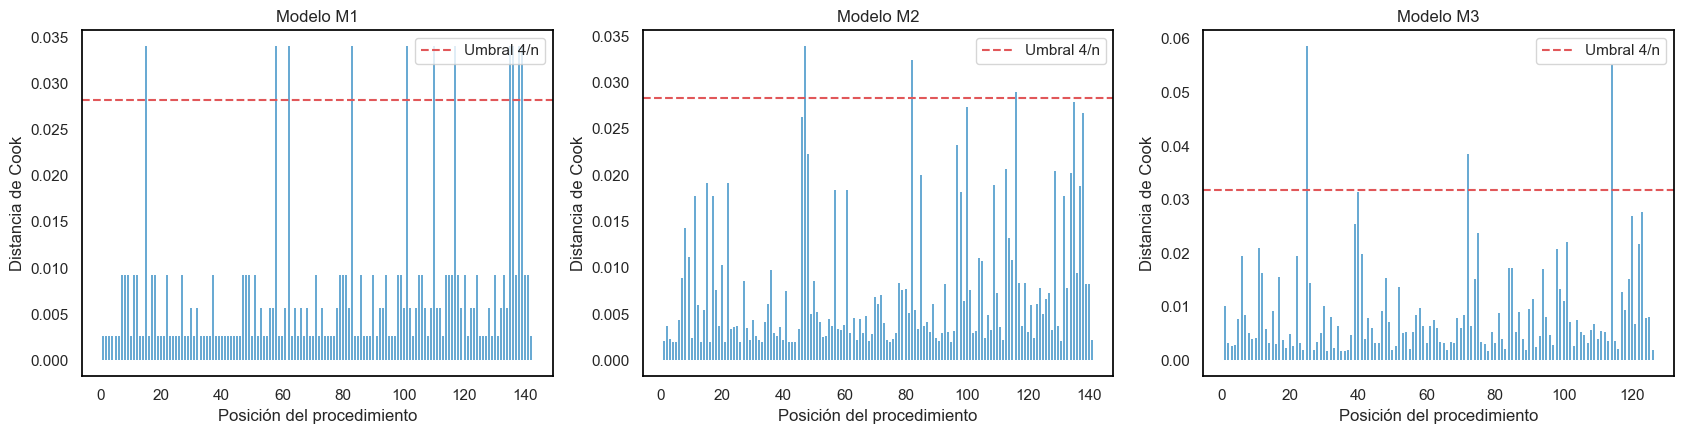

In [19]:

fig, axes = plt.subplots(1, 3, figsize=(17, 4.5))

for ax, (nombre, diagnostico) in zip(
    axes, diagnosticos_influencia.items()
):
    valores = diagnostico["Distancia de Cook"].to_numpy()
    posiciones = np.arange(1, len(valores) + 1)
    umbral = 4 / len(valores)

    ax.vlines(
        posiciones,
        0,
        valores,
        color="#4C9ACB",
        linewidth=1.2
    )

    ax.axhline(
        umbral,
        color="#E15759",
        linestyle="--",
        linewidth=1.5,
        label="Umbral 4/n"
    )

    ax.set_title(f"Modelo {nombre}")
    ax.set_xlabel("Posición del procedimiento")
    ax.set_ylabel("Distancia de Cook")
    ax.grid(False)
    ax.legend(frameon=True)

    for spine in ax.spines.values():
        spine.set_visible(True)
        spine.set_color("black")

plt.tight_layout()
plt.show()


La distribución de la distancia de Cook muestra que la mayoría de los procedimientos presentan valores relativamente bajos en los tres modelos, mientras que un grupo reducido destaca por su mayor influencia sobre el ajuste.

En M1 se observan varios picos de magnitud similar que superan ligeramente el umbral de referencia. Su distribución a lo largo de las observaciones indica que la influencia no se concentra en una única posición del conjunto de datos. En M2, la mayoría de los valores permanece por debajo del umbral y únicamente tres procedimientos lo superan, con distancias máximas cercanas a 0,034.

M3 presenta un comportamiento más heterogéneo, con dos picos particularmente destacados, próximos a 0,059 y 0,055, además de una tercera observación que supera el umbral. Aunque el número de procedimientos señalados por la distancia de Cook es igual al de M2, sus valores máximos son superiores, lo que sugiere una mayor sensibilidad del ajuste a determinadas observaciones.

En general, la figura permite identificar procedimientos que merecen una revisión individual, sin mostrar una concentración generalizada de valores elevados. No obstante, estas distancias no permiten determinar por sí solas si la asociación entre el uso de prótesis biliar y las reintervenciones cambia sustancialmente al excluir cada observación. Para establecerlo, será necesario evaluar específicamente la estabilidad del coeficiente de prótesis.


#### 3.4.2. Estabilidad del coeficiente asociado al uso de prótesis biliar

Con el propósito de evaluar la sensibilidad de la asociación principal frente a observaciones individuales, se realiza un análisis de exclusión sucesiva (*leave-one-out*). Este procedimiento consiste en ajustar nuevamente cada especificación después de retirar temporalmente un procedimiento y comparar el coeficiente estimado para el uso de prótesis con el obtenido en el modelo original.

Se examinan los valores mínimos y máximos de las razones de momios resultantes, así como el cambio relativo máximo respecto a la estimación inicial. Este análisis permite determinar si la asociación estimada depende considerablemente de determinados procedimientos.

Las exclusiones se realizan exclusivamente con fines diagnósticos. Todos los procedimientos elegibles se conservan en los modelos principales.


In [20]:

filas_estabilidad = []
resultados_leave_one_out = {}

for nombre, variables in variables_modelos.items():
    datos = muestras_modelos[nombre].copy()

    X = sm.add_constant(
        datos[variables].astype(float),
        has_constant="add"
    )

    y = datos["Y_REINTERVENCION"].astype(int)

    beta_original = resultados_modelos[nombre].params["X_PROTESIS"]
    or_original = np.exp(beta_original)

    estimaciones = []
    fallos = 0

    for posicion in range(len(datos)):
        mascara = np.ones(len(datos), dtype=bool)
        mascara[posicion] = False

        try:
            modelo_loo = sm.Logit(
                y.iloc[mascara],
                X.iloc[mascara]
            ).fit(
                method="lbfgs",
                maxiter=2000,
                disp=False
            )

            if modelo_loo.mle_retvals.get("converged", False):
                estimaciones.append(
                    np.exp(modelo_loo.params["X_PROTESIS"])
                )
            else:
                fallos += 1

        except (ValueError, np.linalg.LinAlgError):
            fallos += 1

    estimaciones = np.asarray(estimaciones)

    resultados_leave_one_out[nombre] = estimaciones

    if len(estimaciones) > 0:
        cambio_maximo = np.max(
            np.abs(estimaciones - or_original) / or_original
        ) * 100

        filas_estabilidad.append({
            "Modelo": nombre,
            "OR original": or_original,
            "OR mínimo": estimaciones.min(),
            "OR máximo": estimaciones.max(),
            "Cambio máximo (%)": cambio_maximo,
            "Ajustes válidos": len(estimaciones),
            "Ajustes fallidos": fallos
        })

tabla_estabilidad = pd.DataFrame(filas_estabilidad)

display(
    tabla_estabilidad.style
    .hide(axis="index")
    .format({
        "OR original": "{:.3f}",
        "OR mínimo": "{:.3f}",
        "OR máximo": "{:.3f}",
        "Cambio máximo (%)": "{:.2f}"
    })
    .set_caption("Estabilidad del OR de prótesis mediante exclusión sucesiva")
    .set_table_styles([
        {
            "selector": "th",
            "props": [
                ("background-color", "#17365D"),
                ("color", "white"),
                ("text-align", "center"),
                ("border", "1px solid black")
            ]
        },
        {
            "selector": "td",
            "props": [
                ("text-align", "center"),
                ("border", "1px solid black")
            ]
        }
    ])
)


Modelo,OR original,OR mínimo,OR máximo,Cambio máximo (%),Ajustes válidos,Ajustes fallidos
M1,1.299,1.251,1.429,10.00,142,0
M2,1.105,1.022,1.233,11.56,141,0
M3,1.021,0.894,1.146,12.37,126,0


El análisis de exclusión sucesiva permitió evaluar la estabilidad de la asociación entre el uso de prótesis biliar y las reintervenciones frente a la influencia de cada procedimiento. Los tres modelos completaron satisfactoriamente todas las estimaciones, sin registrar fallos de convergencia.

En M1, el OR original de 1,299 osciló entre 1,251 y 1,429 al excluir individualmente las observaciones, con un cambio relativo máximo del 10,00 %. La dirección de la asociación se mantuvo positiva en todos los ajustes, lo que indica que la estimación del modelo sin ajustar no depende exclusivamente de un procedimiento particular.

En M2, el OR varió entre 1,022 y 1,233 respecto a su valor original de 1,105, con una variación máxima del 11,56 %. Aunque la incorporación de covariables produjo una mayor sensibilidad frente a determinadas observaciones, las estimaciones permanecieron por encima de la unidad durante todas las exclusiones individuales.

M3 presentó la mayor variabilidad relativa, con un OR mínimo de 0,894 y máximo de 1,146, frente a la estimación original de 1,021. El cambio máximo alcanzó el 12,37 %, y algunas exclusiones modificaron la dirección de la asociación estimada. Este comportamiento es consistente con una asociación cercana a la unidad, cuya dirección resulta más sensible a pequeñas modificaciones de la muestra.

Los resultados indican que ninguna observación individual produce cambios extremos en la magnitud del OR de prótesis. Sin embargo, la estabilidad es mayor en M1 y M2 que en M3, donde la asociación estimada puede situarse a ambos lados de la unidad. Estos hallazgos complementan los diagnósticos de influencia y permiten continuar con la comparación de los modelos, manteniendo la cautela respecto a la precisión de las estimaciones.


### 3.5. Comparación de los modelos 

Los modelos M1, M2 y M3 presentan diferencias tanto en las covariables incluidas como en el número de procedimientos utilizados para su estimación. Por esta razón, los cambios observados en la asociación entre el uso de prótesis biliar y las reintervenciones no pueden atribuirse exclusivamente al ajuste estadístico.

Para examinar este aspecto, se realiza una comparación complementaria utilizando una muestra común, conformada por los procedimientos con información completa para todas las variables de M3. Sobre esta misma muestra se estiman nuevamente las tres especificaciones, manteniendo sus respectivos conjuntos de predictores.

Se comparan las razones de momios del uso de prótesis, sus intervalos de confianza y los valores p. Este procedimiento permite evaluar el comportamiento de la asociación al incorporar covariables sin introducir diferencias en la composición de la muestra analizada.


In [21]:

muestra_comun = muestras_modelos["M3"].copy()

filas_comparacion = []
modelos_muestra_comun = {}

for nombre, variables in variables_modelos.items():
    X = sm.add_constant(
        muestra_comun[variables].astype(float),
        has_constant="add"
    )

    y = muestra_comun["Y_REINTERVENCION"].astype(int)

    modelo = sm.Logit(y, X).fit(
        method="lbfgs",
        maxiter=2000,
        disp=False
    )

    modelos_muestra_comun[nombre] = modelo

    beta = modelo.params["X_PROTESIS"]
    ic = modelo.conf_int().loc["X_PROTESIS"]

    filas_comparacion.append({
        "Modelo": nombre,
        "N": len(y),
        "Eventos": int(y.sum()),
        "OR prótesis": np.exp(beta),
        "IC 95 % inferior": np.exp(ic.iloc[0]),
        "IC 95 % superior": np.exp(ic.iloc[1]),
        "Valor p": modelo.pvalues["X_PROTESIS"]
    })

tabla_comparacion_comun = pd.DataFrame(filas_comparacion)

display(
    tabla_comparacion_comun.style
    .hide(axis="index")
    .format({
        "OR prótesis": "{:.3f}",
        "IC 95 % inferior": "{:.3f}",
        "IC 95 % superior": "{:.3f}",
        "Valor p": "{:.3f}"
    })
    .set_caption("Asociación entre prótesis y reintervención en una muestra común")
    .set_table_styles([
        {
            "selector": "th",
            "props": [
                ("background-color", "#17365D"),
                ("color", "white"),
                ("text-align", "center"),
                ("border", "1px solid black")
            ]
        },
        {
            "selector": "td",
            "props": [
                ("text-align", "center"),
                ("border", "1px solid black")
            ]
        }
    ])
)


Modelo,N,Eventos,OR prótesis,IC 95 % inferior,IC 95 % superior,Valor p
M1,126,45,1.225,0.518,2.897,0.644
M2,126,45,1.082,0.448,2.613,0.862
M3,126,45,1.021,0.418,2.493,0.964


La comparación sobre una muestra común de 126 procedimientos, con 45 eventos de reintervención, permitió examinar el comportamiento de la asociación entre el uso de prótesis biliar y las reintervenciones sin introducir diferencias en el conjunto de observaciones analizadas.

En M1, el uso de prótesis presentó un OR de 1,225 (IC 95 %: 0,518–2,897; p = 0,644). Al incorporar edad, sexo y antecedente de colecistectomía, el OR disminuyó a 1,082 (IC 95 %: 0,448–2,613; p = 0,862). Finalmente, con la inclusión de bilirrubina total al ingreso, la estimación se aproximó a la unidad (OR = 1,021; IC 95 %: 0,418–2,493; p = 0,964).

La disminución progresiva del OR también se observa al utilizar exactamente los mismos procedimientos, por lo que no puede atribuirse únicamente a las diferencias de tamaño muestral identificadas en la comparación inicial. Sin embargo, los cambios entre modelos no deben interpretarse exclusivamente como evidencia de confusión, debido a las propiedades de las razones de momios en la regresión logística.

En las tres especificaciones, los intervalos de confianza incluyen la unidad y no se identifican asociaciones estadísticamente significativas. Las estimaciones ajustadas se mantienen próximas a un OR de 1, aunque su incertidumbre impide descartar asociaciones de mayor magnitud en cualquiera de las dos direcciones.

Los resultados indican que la asociación estimada entre el uso de prótesis biliar y las reintervenciones es pequeña después del ajuste por las covariables consideradas. Su comportamiento es relativamente consistente entre las especificaciones evaluadas, sin que los datos proporcionen evidencia estadística suficiente para establecer una asociación distinta de la unidad.


### 3.6. Evaluación del desempeño de los modelos

Se evalúa el desempeño de los tres modelos de regresión logística mediante el análisis de su capacidad discriminativa y de clasificación. Para ello, se construyen curvas ROC y se examina el comportamiento de la sensibilidad y la especificidad frente a diferentes umbrales de decisión, utilizando la muestra común de 126 procedimientos.


#### 3.6.1. Curvas ROC y área bajo la curva (AUC)

Se construyen las curvas ROC de los modelos M1, M2 y M3 para evaluar su capacidad de distinguir entre procedimientos con y sin reintervención biliar. El área bajo la curva (AUC) permite comparar su capacidad discriminativa sin depender de un umbral de clasificación específico.


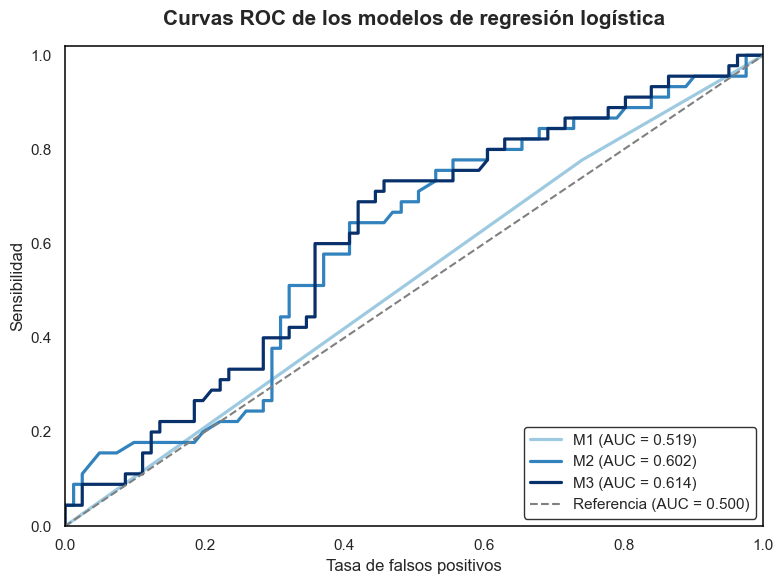

Modelo,N,Eventos,AUC
M1,126,45,0.519
M2,126,45,0.602
M3,126,45,0.614


In [31]:

from sklearn.metrics import roc_curve, roc_auc_score
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.api as sm

predicciones_comunes = {}
resultados_auc = []

fig, ax = plt.subplots(figsize=(8, 6))


colores = {
    "M1": "#9ECAE1",
    "M2": "#3182BD",
    "M3": "#08306B"
}

for nombre, variables in variables_modelos.items():
    X = sm.add_constant(
        muestra_comun[variables].astype(float),
        has_constant="add"
    )

    y_real = muestra_comun["Y_REINTERVENCION"].astype(int).to_numpy()
    probabilidades = np.asarray(modelos_muestra_comun[nombre].predict(X))

    predicciones_comunes[nombre] = {
        "y_real": y_real,
        "probabilidades": probabilidades
    }

    fpr, tpr, _ = roc_curve(y_real, probabilidades)
    auc = roc_auc_score(y_real, probabilidades)

    resultados_auc.append({
        "Modelo": nombre,
        "N": len(y_real),
        "Eventos": int(y_real.sum()),
        "AUC": auc
    })

    ax.plot(
        fpr,
        tpr,
        color=colores[nombre],
        linewidth=2.3,
        label=f"{nombre} (AUC = {auc:.3f})"
    )

ax.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    color="gray",
    linewidth=1.5,
    label="Referencia (AUC = 0.500)"
)

ax.set_title(
    "Curvas ROC de los modelos de regresión logística",
    fontsize=15,
    fontweight="bold",
    pad=15
)

ax.set_xlabel("Tasa de falsos positivos", fontsize=12)
ax.set_ylabel("Sensibilidad", fontsize=12)

ax.set_xlim(0, 1)
ax.set_ylim(0, 1.02)

ax.legend(
    loc="lower right",
    frameon=True,
    edgecolor="black"
)

ax.grid(False)

for spine in ax.spines.values():
    spine.set_color("black")
    spine.set_linewidth(1.1)

plt.tight_layout()
plt.show()

tabla_auc = pd.DataFrame(resultados_auc)

display(
    tabla_auc.style
    .hide(axis="index")
    .format({"AUC": "{:.3f}"})
    .set_caption("Capacidad discriminativa de los modelos en la muestra común")
    .set_table_styles([
        {
            "selector": "table",
            "props": [
                ("border-collapse", "collapse"),
                ("margin", "15px auto")
            ]
        },
        {
            "selector": "th",
            "props": [
                ("background-color", "#17365D"),
                ("color", "white"),
                ("text-align", "center"),
                ("padding", "9px 14px"),
                ("border", "1px solid black")
            ]
        },
        {
            "selector": "td",
            "props": [
                ("text-align", "center"),
                ("padding", "8px 14px"),
                ("border", "1px solid black")
            ]
        }
    ])
)


Las curvas ROC muestran diferencias moderadas en la capacidad discriminativa de los tres modelos. M1 presentó el desempeño más bajo, con un AUC de 0.519, muy cercano al valor de referencia de 0.50, lo que indica que el uso de prótesis biliar, considerado de manera individual, apenas permite distinguir entre procedimientos con y sin reintervención.

Al incorporar las covariables clínicas, la capacidad discriminativa aumentó ligeramente. M2 alcanzó un AUC de 0.602, mientras que M3 obtuvo el valor más alto, con 0.614. Aunque estos resultados muestran una mejora respecto al modelo inicial, las curvas permanecen relativamente próximas a la diagonal de referencia, lo que refleja una capacidad limitada para diferenciar ambos desenlaces.

La incorporación de variables adicionales produjo una mejora discreta en la discriminación, sin alcanzar un desempeño suficientemente sólido para respaldar su utilización como herramienta de predicción individual. Estos resultados corresponden al desempeño observado en la muestra utilizada para ajustar los modelos.


#### 3.6.2. Análisis de sensibilidad al umbral de clasificación

Se examina el comportamiento de la sensibilidad y la especificidad de los tres modelos al modificar el umbral de clasificación entre 0.10 y 0.50. Este análisis permite identificar cómo cambia la detección de reintervenciones y la clasificación de procedimientos sin eventos según el punto de corte seleccionado.


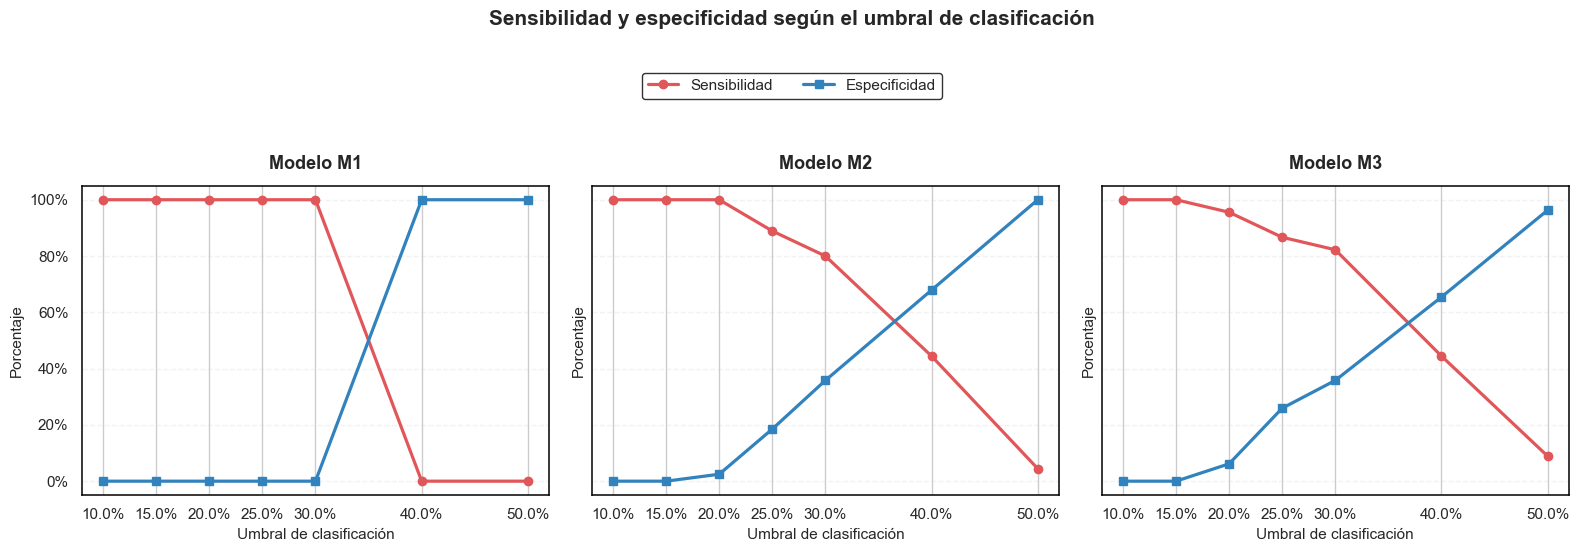

Modelo,Umbral,Sensibilidad,Especificidad,VP,FP,FN,VN
M1,0.10,100.00%,0.00%,45,81,0,0
M1,0.15,100.00%,0.00%,45,81,0,0
M1,0.20,100.00%,0.00%,45,81,0,0
M1,0.25,100.00%,0.00%,45,81,0,0
M1,0.30,100.00%,0.00%,45,81,0,0
M1,0.40,0.00%,100.00%,0,0,45,81
M1,0.50,0.00%,100.00%,0,0,45,81
M2,0.10,100.00%,0.00%,45,81,0,0
M2,0.15,100.00%,0.00%,45,81,0,0
M2,0.20,100.00%,2.47%,45,79,0,2


Modelo,Umbral,Sensibilidad,Especificidad,VP,FP,FN,VN
M1,0.10,100.00%,0.00%,45,81,0,0
M1,0.15,100.00%,0.00%,45,81,0,0
M1,0.20,100.00%,0.00%,45,81,0,0
M1,0.25,100.00%,0.00%,45,81,0,0
M1,0.30,100.00%,0.00%,45,81,0,0
M1,0.40,0.00%,100.00%,0,0,45,81
M1,0.50,0.00%,100.00%,0,0,45,81
M2,0.10,100.00%,0.00%,45,81,0,0
M2,0.15,100.00%,0.00%,45,81,0,0
M2,0.20,100.00%,2.47%,45,79,0,2


In [33]:

from sklearn.metrics import confusion_matrix
from matplotlib.ticker import PercentFormatter
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

umbrales = [0.10, 0.15, 0.20, 0.25, 0.30, 0.40, 0.50]

resultados_umbrales = []

for nombre, valores in predicciones_comunes.items():
    y_real = np.asarray(valores["y_real"])
    probabilidades = np.asarray(valores["probabilidades"])

    for umbral in umbrales:
        y_pred = (probabilidades >= umbral).astype(int)

        vn, fp, fn, vp = confusion_matrix(
            y_real, y_pred, labels=[0, 1]
        ).ravel()

        sensibilidad = vp / (vp + fn) if vp + fn else np.nan
        especificidad = vn / (vn + fp) if vn + fp else np.nan

        resultados_umbrales.append({
            "Modelo": nombre,
            "Umbral": umbral,
            "Sensibilidad": sensibilidad,
            "Especificidad": especificidad,
            "VP": vp,
            "FP": fp,
            "FN": fn,
            "VN": vn
        })

tabla_umbrales = pd.DataFrame(resultados_umbrales)

fig, axes = plt.subplots(1, 3, figsize=(16, 5), sharex=True, sharey=True)

for ax, nombre in zip(axes, predicciones_comunes):
    datos = tabla_umbrales[tabla_umbrales["Modelo"] == nombre]

    ax.plot(
        datos["Umbral"],
        datos["Sensibilidad"],
        color="#E15759",
        marker="o",
        linewidth=2.3,
        markersize=6,
        label="Sensibilidad"
    )

    ax.plot(
        datos["Umbral"],
        datos["Especificidad"],
        color="#3182BD",
        marker="s",
        linewidth=2.3,
        markersize=6,
        label="Especificidad"
    )

    ax.set_title(
        f"Modelo {nombre}",
        fontsize=13,
        fontweight="bold",
        pad=12
    )

    ax.set_ylim(-0.05, 1.05)
    ax.set_xlim(0.08, 0.52)
    ax.set_xticks(umbrales)

    ax.yaxis.set_major_formatter(PercentFormatter(1))
    ax.xaxis.set_major_formatter(PercentFormatter(1))

    ax.set_xlabel("Umbral de clasificación", fontsize=11)
    ax.set_ylabel("Porcentaje", fontsize=11)

    ax.grid(axis="y", linestyle="--", alpha=0.25)

    for spine in ax.spines.values():
        spine.set_color("black")
        spine.set_linewidth(1.1)

handles, labels = axes[0].get_legend_handles_labels()

fig.legend(
    handles,
    labels,
    loc="upper center",
    bbox_to_anchor=(0.5, 0.99),
    ncol=2,
    frameon=True,
    edgecolor="black"
)

fig.suptitle(
    "Sensibilidad y especificidad según el umbral de clasificación",
    fontsize=15,
    fontweight="bold",
    y=1.10
)

plt.tight_layout(rect=[0, 0, 1, 0.92])
plt.show()


estilos_umbrales = [
    {
        "selector": "table",
        "props": [
            ("border-collapse", "collapse"),
            ("margin", "15px auto"),
            ("font-family", "Arial, sans-serif"),
            ("font-size", "12px"),
            ("border", "1.5px solid black")
        ]
    },
    {
        "selector": "caption",
        "props": [
            ("caption-side", "top"),
            ("text-align", "center"),
            ("font-weight", "bold"),
            ("font-size", "13px"),
            ("color", "white"),
            ("padding", "10px")
        ]
    },
    {
        "selector": "th.col_heading",
        "props": [
            ("background-color", "#17365D"),
            ("color", "#FFFFFF"),
            ("font-weight", "bold"),
            ("text-align", "center"),
            ("padding", "9px 12px"),
            ("border", "1px solid black")
        ]
    },
    {
        "selector": "td",
        "props": [
            ("color", "#111111"),
            ("text-align", "center"),
            ("padding", "7px 12px"),
            ("border", "1px solid black")
        ]
    },
    {
        "selector": "tbody tr:nth-child(odd) td",
        "props": [
            ("background-color", "#FFFFFF"),
            ("color", "#111111")
        ]
    },
    {
        "selector": "tbody tr:nth-child(even) td",
        "props": [
            ("background-color", "#EAF1F8"),
            ("color", "#111111")
        ]
    }
]

separadores = [
    {
        "selector": f"tbody tr:nth-child({fila}) td",
        "props": [
            ("border-top", "2.5px solid #17365D")
        ]
    }
    for fila in [8, 15]
]

tabla_umbrales_estilizada = (
    tabla_umbrales.style
    .hide(axis="index")
    .format({
        "Umbral": "{:.2f}",
        "Sensibilidad": "{:.2%}",
        "Especificidad": "{:.2%}"
    })
    .set_caption(
        "Sensibilidad y especificidad según el umbral de clasificación"
    )
    .set_table_styles(estilos_umbrales + separadores)
    .set_properties(
        subset=["Modelo"],
        **{"font-weight": "bold"}
    )
)

display(tabla_umbrales_estilizada)


display(
    tabla_umbrales.style
    .hide(axis="index")
    .format({
        "Umbral": "{:.2f}",
        "Sensibilidad": "{:.2%}",
        "Especificidad": "{:.2%}"
    })
    .set_caption(
        "Sensibilidad y especificidad de los modelos según el umbral de clasificación"
    )
    .set_table_styles(estilos_umbrales + separadores)
    .set_properties(
        subset=["Modelo"],
        **{"font-weight": "bold"}
    )
)


El análisis muestra que la sensibilidad y la especificidad de los tres modelos cambian considerablemente según el umbral de clasificación utilizado. M1 presenta el comportamiento más limitado: con umbrales entre 0.10 y 0.30 identifica las 45 reintervenciones, pero clasifica incorrectamente los 81 procedimientos sin eventos. A partir de 0.40 ocurre lo contrario, pues deja de identificar reintervenciones y clasifica todos los procedimientos como negativos.

Los modelos M2 y M3 muestran un comportamiento más gradual. Con un umbral de 0.30, M2 alcanza una sensibilidad del 80.00 % y una especificidad del 35.80 %, mientras que M3 obtiene valores del 82.22 % y 35.80 %, respectivamente. Aunque ambos identifican la mayoría de las reintervenciones, también generan 52 falsos positivos. Al aumentar el umbral a 0.40, la especificidad mejora hasta el 67.90 % en M2 y el 65.43 % en M3, pero la sensibilidad disminuye al 44.44 % en ambos casos.

Con el umbral convencional de 0.50, la sensibilidad cae al 0 % en M1, 4.44 % en M2 y 8.89 % en M3, mientras que la especificidad supera el 96 % en las tres especificaciones. En conjunto, los resultados muestran que ninguno de los umbrales evaluados permite alcanzar simultáneamente una sensibilidad y una especificidad elevadas. Aunque M2 y M3 presentan un comportamiento más flexible que M1, su capacidad para identificar reintervenciones sigue siendo limitada, especialmente cuando se busca reducir el número de falsos positivos.

## 4. Conclusiones

Se evaluó la asociación entre el uso de prótesis biliar y la necesidad de reintervención mediante tres modelos de regresión logística. El análisis partió de una cohorte de 145 procedimientos, de los cuales 142 contaban con información suficiente para establecer la exposición principal. Se consideraron la edad, el sexo, el antecedente de colecistectomía y la bilirrubina total al ingreso como covariables de ajuste.

Los resultados no mostraron una asociación estadísticamente significativa entre el uso de prótesis biliar y las reintervenciones. En el modelo sin ajustar se obtuvo un OR de 1.299, que disminuyó progresivamente hasta 1.021 al incorporar las covariables clínicas. Esta reducción también se observó al comparar los tres modelos sobre una muestra común de 126 procedimientos, lo que permitió comprobar que las diferencias no se debían únicamente a los cambios en el tamaño muestral. Sin embargo, la amplitud de los intervalos de confianza impide descartar asociaciones de mayor magnitud.

Los tres modelos alcanzaron una convergencia numérica satisfactoria. Los diagnósticos de influencia y el análisis *leave-one-out* mostraron que las estimaciones de M1 y M2 fueron relativamente estables frente a la exclusión de observaciones individuales. M3 presentó una mayor sensibilidad, con variaciones que llegaron a modificar la dirección de la asociación estimada, aunque sin cambios extremos en su magnitud.

La evaluación del desempeño permitió identificar otras limitaciones. Las curvas ROC mostraron una capacidad discriminativa reducida, con valores AUC de 0.519, 0.602 y 0.614 para M1, M2 y M3, respectivamente. La incorporación de covariables mejoró ligeramente la discriminación, pero ninguno de los modelos logró distinguir con suficiente claridad los procedimientos con y sin reintervención. El análisis de los umbrales de clasificación confirmó esta dificultad: los puntos de corte que permitieron identificar una mayor proporción de reintervenciones también generaron numerosos falsos positivos.

Entre las principales limitaciones se encuentran el tamaño de la muestra, la reducción de observaciones al incorporar la bilirrubina total y las diferencias clínicas entre los grupos con y sin prótesis.

En conclusión, **los resultados no proporcionaron evidencia estadística suficiente para establecer una asociación entre el uso de prótesis biliar y la necesidad de reintervención en la cohorte analizada**. Aunque el ajuste por características clínicas permitió examinar esta relación desde diferentes especificaciones, las estimaciones conservaron una incertidumbre considerable y los modelos mostraron una capacidad predictiva limitada. Estos hallazgos describen el comportamiento observado en la cohorte y no permiten atribuir al uso de prótesis un efecto causal sobre las reintervenciones biliares.